# Error analysis of one segmentation model (v2 dataset)

Where does the mask AP of a trained model go? This notebook takes the test
predictions of **one** run (a Colab run folder downloaded from Drive) and breaks
its errors down:

1. **TIDE decomposition** (Bolya et al., ECCV 2020) — every non-TP detection gets
   one error type (*cls*, *loc*, *both*, *dupe*, *bkg*) and every unmatched GT is a
   *miss*; each type is fixed by an oracle in isolation and AP recomputed: the
   gain ΔAP is the cost of that error type. Our implementation
   (`utils/error_analysis.py`) is first checked to reproduce pycocotools mask AP
   exactly. Plus a *mask quality* oracle (all TP masks replaced by GT masks).
2. **Class confusions** — which class pairs are swapped (desk ↔ table, sofa ↔ chair,
   …) and what a merged pair would score.
3. **AP by object size and by sensor** (kv1 / kv2 / xtion / realsense).
4. **Bootstrap 95% CI** of mask AP over test images — the noise floor for
   comparing runs.
5. **Galleries** — high-score background FPs, missed GT, best / worst images.
6. **TIDE profile of Mask R-CNN vs YOLOv8-seg** (when both runs are present).

All headline metrics come from the shared evaluator `utils/evaluate_predictions.py`.

**Parameters** (next cell, or environment variables for headless runs):
`VKR_RUNS_ROOT` — folder with the downloaded runs (default `~/Downloads`);
`VKR_MODEL_DIR` — the run to analyse (default: the Mask R-CNN run with the
highest **validation** mask AP on the std10 validation split, whatever class
configuration it was trained on — the rule of notebook 10); `VKR_COMPARE_DIR` — the
run for the TIDE comparison (default: the YOLOv8-seg std10 run). The analysis is
always done on the std10 GT (`EVAL_CONFIG`): a min400 model's predictions of the
10 extra classes and on min400-only images are dropped by the evaluator's loader. Env: conda `university`, no GPU.
Outputs: `outputs/error_analysis/<run_name>/`.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.evaluate_predictions as ep
import utils.error_analysis as ea

%matplotlib inline
ea.set_plot_style()
pd.set_option("display.width", 160, "display.max_columns", 30)

In [2]:
# ---- parameters -------------------------------------------------------------
RUNS_ROOT   = Path(os.environ.get("VKR_RUNS_ROOT", "~/Downloads")).expanduser()
MODEL_DIR   = os.environ.get("VKR_MODEL_DIR")     # None -> best Mask R-CNN by std10 val AP
COMPARE_DIR = os.environ.get("VKR_COMPARE_DIR")   # None -> the YOLOv8-seg std10 run, if any
EVAL_CONFIG = "std10"                             # GT the model is analysed on (the thesis task)
SPLIT       = "test"

DATASET_ROOT = ea.DATASET_ROOT                    # images for the galleries
FULL_COCO    = Path("outputs/sunrgbd_instances_all.json")   # all classes (grey outlines)
OUT_ROOT     = Path("outputs/error_analysis")

CONF      = 0.5      # confidence threshold for P/R/F1, confusion matrix, qualitative views
IOU       = 0.5      # matching threshold (mirrors evaluate_predictions.py)
N_BOOT    = 1000     # bootstrap resamples over images
N_GALLERY = 16       # tiles per gallery
SEED      = 0

## Which run

Model selection rule of the thesis: **validation mask AP** on the std10 validation
split (COCOeval on `val_predictions.json`); the test split is used only for
reporting. Without `MODEL_DIR` the notebook evaluates the validation predictions of
every Mask R-CNN run found — std10 and min400 (the class configuration is a
hyperparameter; a min400 model is scored on the std10 GT) — and picks the best one,
as notebook 10 does.

In [3]:
runs = ea.discover_runs(RUNS_ROOT)
by_name = {r.name: r for r in runs}

if MODEL_DIR:
    run = ea.parse_run(Path(MODEL_DIR).expanduser())
    assert run is not None and "test" in run.files, f"not a run folder with test predictions: {MODEL_DIR}"
else:
    cands = [r for r in runs if r.is_maskrcnn]
    assert cands, f"no Mask R-CNN run under {RUNS_ROOT}"
    sel_rows = {}
    for r in cands:
        if "val" not in r.files:
            print(f"[note] {r.name}: no val_predictions.json -> cannot take part in selection")
            continue
        gt_val = ea.load_coco(r.gt_path("val", EVAL_CONFIG))
        sel_rows[r.name] = {"val_mask_AP": ea.segm_ap(gt_val, ea.load_preds(r.files["val"], gt_val))["AP"]}
    sel = pd.DataFrame(sel_rows).T
    best = ea.select_best(sel, pd.Series(True, index=sel.index), "val_mask_AP")
    print("\nSelection by validation mask AP:")
    print(sel.sort_values("val_mask_AP", ascending=False).round(4).to_string())
    run = by_name[best]

OUT_DIR = OUT_ROOT / (run.name + ("" if run.config == EVAL_CONFIG else f"_on_{EVAL_CONFIG}"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
GT_PATH = run.gt_path(SPLIT, EVAL_CONFIG)
print(f"\nAnalysed run: {run.name}  ({run.label})")
print(f"GT:  {GT_PATH}\nOut: {OUT_DIR}")

[*] 5 run(s) found under /Users/polina_sushko/Downloads
[!] Dropped predictions outside GT: 2799 by image_id, 13411 by category_id
[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/val_predictions.json: 26153 predictions on 1283/1284 GT images


[i] v2_maskrcnn_detectron2_std10_R_101_FPN_3x/val_predictions.json: 26881 predictions on 1283/1284 GT images


[i] v2_maskrcnn_detectron2_std10_R_50_FPN_3x/val_predictions.json: 26229 predictions on 1283/1284 GT images


[i] v2_maskrcnn_torchvision_std10/val_predictions.json: 27849 predictions on 1283/1284 GT images



Selection by validation mask AP:
                                            val_mask_AP
v2_maskrcnn_detectron2_min400_R_101_FPN_3x       0.2570
v2_maskrcnn_detectron2_std10_R_101_FPN_3x        0.2476
v2_maskrcnn_torchvision_std10                    0.2455
v2_maskrcnn_detectron2_std10_R_50_FPN_3x         0.2437

Analysed run: v2_maskrcnn_detectron2_min400_R_101_FPN_3x  (Mask R-CNN (Detectron2) R_101_FPN_3x min400)
GT:  /Users/polina_sushko/My_work/University/ВКР/Object-segmentation-using-a-two-stage-Mask-R-CNN-model/notebooks/outputs/splits/instances_test.json
Out: outputs/error_analysis/v2_maskrcnn_detectron2_min400_R_101_FPN_3x_on_std10


In [4]:
coco_gt = ea.load_coco(GT_PATH)
NAMES = ea.class_names(coco_gt)
preds = ea.load_preds(run.files[SPLIT], coco_gt)

ev = ea.evaluate(coco_gt, preds, conf=CONF, iou=IOU)
print("\nCOCO metrics (evaluate_predictions.py):")
print(pd.DataFrame({"segm": ev["segm"], "bbox": ev["bbox"]}).T.round(4).to_string())
print(f"mean matched IoU (conf >= {CONF}): {ev['mean_iou']:.4f}")

[!] Dropped predictions outside GT: 3120 by image_id, 13466 by category_id
[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/test_predictions.json: 25058 predictions on 1286/1287 GT images



COCO metrics (evaluate_predictions.py):
          AP    AP50    AP75     APs     APm     APl
segm  0.2665  0.4272  0.2861  0.0309  0.1075  0.3526
bbox  0.2893  0.4329  0.3150  0.0389  0.1401  0.3772
mean matched IoU (conf >= 0.5): 0.7900


---
## 1. TIDE decomposition

Error types at foreground IoU $t_f = 0.5$, background IoU $t_b = 0.1$ (mask IoU):

| type | definition | oracle fix |
|---|---|---|
| **cls** | IoU ≥ $t_f$ with a GT of *another* class | class corrected |
| **loc** | $t_b$ ≤ IoU < $t_f$ with a GT of the correct class | mask replaced by the GT mask |
| **both** | $t_b$ ≤ IoU < $t_f$ with a GT of another class | detection removed |
| **dupe** | IoU ≥ $t_f$ with a correct-class GT already matched by a higher score | detection removed |
| **bkg** | IoU < $t_b$ with every GT | detection removed |
| **miss** | GT neither matched nor the target of a cls / loc error | GT removed |

A cls / loc fix that would hit an already matched GT removes the detection
instead (it would be a duplicate). ΔAP is reported for AP50 and for
AP@[.50:.95]; the deltas are not additive (errors overlap). The extra row
*mask quality* replaces every TP mask (at IoU 0.5) by its GT mask: it
measures how much AP@[.50:.95] is lost purely to mask precision.

First, the self-check: our matcher + AP must equal pycocotools.

In [5]:
data = ea.TideData(coco_gt, preds)
chk = ea.check_tide_vs_cocoeval(data)
print(chk.to_string(float_format=lambda v: f"{v:.10f}"))
print(f"max per-class |diff| = {chk.attrs['max_per_class_diff']:.2e}")
assert chk.attrs["exact"], "TIDE AP does not reproduce pycocotools — do not trust the decomposition"
print("[ok] TIDE implementation reproduces pycocotools mask AP exactly")
chk.to_csv(OUT_DIR / "tide_check_vs_pycocotools.csv")

      pycocotools     tide_lib     abs_diff
AP   0.2664533351 0.2664533351 0.0000000000
AP50 0.4271774895 0.4271774895 0.0000000000
max per-class |diff| = 1.11e-16
[ok] TIDE implementation reproduces pycocotools mask AP exactly


In [6]:
tide = ea.run_tide(data)
summary, per_class, rec, gt_status = (tide["summary"], tide["per_class"],
                                      tide["records"], tide["gt_status"])
summary.to_csv(OUT_DIR / "tide_summary.csv", index=False)
per_class.to_csv(OUT_DIR / "tide_per_class.csv")
rec.to_csv(OUT_DIR / "tide_records.csv.gz", index=False)

print(f"base AP = {tide['base_AP']:.4f}, AP50 = {tide['base_AP50']:.4f}")
print(summary.round(4).to_string(index=False))

  cls   dAP50 +0.0614  dAP +0.0264


  loc   dAP50 +0.0893  dAP +0.0606


  both  dAP50 +0.0064  dAP +0.0033


  dupe  dAP50 +0.0018  dAP -0.0021


  bkg   dAP50 +0.0988  dAP +0.0584


  miss  dAP50 +0.0731  dAP +0.0459


base AP = 0.2665, AP50 = 0.4272
                        error  count  count_score>0.5  dAP50     dAP
                          cls   2235            347.0 0.0614  0.0264
                          loc   4501            960.0 0.0893  0.0606
                         both   2125            211.0 0.0064  0.0033
                         dupe   1492             71.0 0.0018 -0.0021
                          bkg  11015           1360.0 0.0988  0.0584
                         miss    505              NaN 0.0731  0.0459
mask quality (TP masks -> GT)   3690           2670.0 0.0000  0.1607


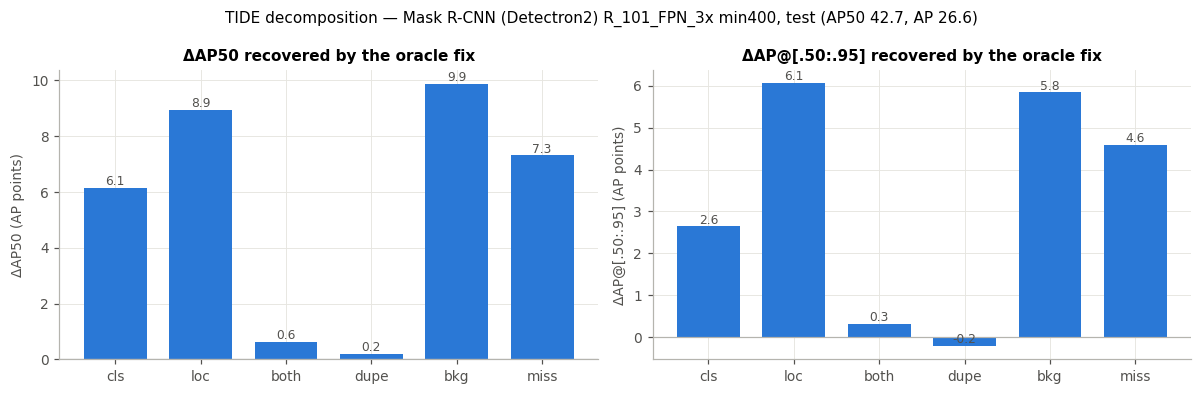

In [7]:
def plot_tide_bars(tables: dict, path: Path, title: str):
    # tables: label -> summary DataFrame; grouped bars per error type, one panel per metric
    errs = ea.TIDE_ERRORS
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
    n = len(tables)
    width = 0.8 / n
    for ax, col, lab in [(axes[0], "dAP50", "ΔAP50"), (axes[1], "dAP", "ΔAP@[.50:.95]")]:
        x = np.arange(len(errs))
        for k, (name, s) in enumerate(tables.items()):
            v = s.set_index("error").loc[errs, col].values * 100
            ax.bar(x + (k - (n - 1) / 2) * width, v, width * 0.92, label=name,
                   color=ea.PALETTE[k])
            if n == 1:
                for xi, vi in zip(x, v):
                    ax.text(xi, vi, f"{vi:.1f}", ha="center", va="bottom", fontsize=8,
                            color="#52514e")
        ax.set_xticks(x, errs)
        ax.set_ylabel(f"{lab} (AP points)")
        ax.set_title(f"{lab} recovered by the oracle fix")
        ax.axhline(0, color="#b5b4ae", lw=0.8)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    if n > 1:
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=n, bbox_to_anchor=(0.5, -0.06))
    fig.savefig(path)
    plt.show()

plot_tide_bars({run.label: summary}, OUT_DIR / "tide_dap.png",
               f"TIDE decomposition — {run.label}, {SPLIT} "
               f"(AP50 {tide['base_AP50']*100:.1f}, AP {tide['base_AP']*100:.1f})")

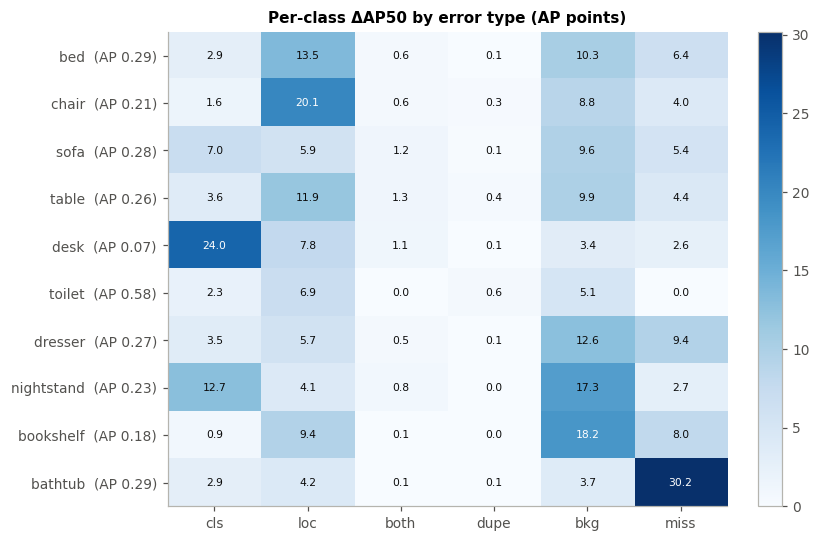

            n_gt     AP   AP50  tp@0.5  miss  mean_tp_iou  n_cls>0.3  n_loc>0.3  n_both>0.3  n_dupe>0.3  n_bkg>0.3
class                                                                                                             
bed          222  0.289  0.490     165    26        0.805         40         42          17           9        111
chair       2651  0.215  0.446    2031   221        0.758        158       1083         149         151       1267
sofa         325  0.282  0.424     246    38        0.829        131         58          46           9        194
table       1131  0.260  0.453     849   103        0.781        226        242         163          80        618
desk         381  0.069  0.137     167    61        0.748         94         44          56           4         98
toilet        39  0.579  0.811      37     0        0.841          1          8           0           1          6
dresser      101  0.267  0.409      68    19        0.847         16         10 

In [8]:
# per-class cost of each error type (ΔAP50, AP points)
cols = [f"dAP50_{e}" for e in ea.TIDE_ERRORS]
M = per_class[cols].values * 100
fig, ax = plt.subplots(figsize=(7.5, 0.38 * len(per_class) + 1.2))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(np.nanmax(M), 1e-6), aspect="auto")
ax.set_xticks(range(len(cols)), ea.TIDE_ERRORS)
ax.set_yticks(range(len(per_class)), [f"{c}  (AP {a:.2f})" for c, a in zip(per_class.index, per_class.AP)])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=7,
                color="white" if M[i, j] > 0.6 * np.nanmax(M) else "#0b0b0b")
ax.grid(False)
ax.set_title("Per-class ΔAP50 by error type (AP points)")
fig.colorbar(im, fraction=0.04)
fig.tight_layout(); fig.savefig(OUT_DIR / "tide_per_class_dap50.png"); plt.show()

print(per_class[["n_gt", "AP", "AP50", "tp@0.5", "miss", "mean_tp_iou"] +
                [f"n_{t}>0.3" for t in ea.TIDE_ERRORS[:-1]]].round(3).to_string())

**Background FPs by score band.** How much AP the background detections of
each confidence band cost — the high-score band is the one that the visual audit
below is about.

In [9]:
bks = ea.bkg_by_score(data, rec, gt_status)
bks.to_csv(OUT_DIR / "bkg_by_score.csv", index=False)
print(bks.round(4).to_string(index=False))

score_band  n_bkg  dAP50    dAP
  [0.8, 1)    459 0.0381 0.0234
[0.5, 0.8)    901 0.0287 0.0171
[0.3, 0.5)   1115 0.0094 0.0052
  [0, 0.3)   8540 0.0092 0.0049
  [0.5, 1)   1360 0.0701 0.0425


---
## 2. Class confusions

TIDE *cls* errors (IoU ≥ 0.5 with a GT of another class, score > 0.3) by
(predicted, GT) pair, and the evaluator's confusion matrix at conf ≥ 0.5.
The **merged-pair AP** relabels both classes of a pair to one (GT and
predictions) — if it is far above the instance-weighted mean of the separate
APs, the pair is mostly a *labeling* ambiguity rather than a model failure.

In [10]:
pairs = ea.confusion_pairs(rec, min_score=0.3)
pairs.to_csv(OUT_DIR / "confusion_pairs.csv", index=False)
print("Top class confusions (TIDE cls errors, score > 0.3):")
print(pairs.head(15).to_string(index=False))

cm = pd.DataFrame(ev["confusion"], index=ev["cat_names"] + ["background"],
                  columns=ev["cat_names"] + ["missed"])
cm.to_csv(OUT_DIR / "confusion_matrix.csv")
ep.plot_confusion(ev["confusion"], ev["cat_names"], IOU, CONF, OUT_DIR / "confusion_matrix.png")
core = cm.iloc[:-1, :-1]
off = core.where(~np.eye(len(core), dtype=bool), 0)
top = off.stack().sort_values(ascending=False).head(8)
print(f"\nLargest off-diagonal cells of the confusion matrix (conf >= {CONF}):")
print(top.rename("n").to_string())

merged = ea.merged_pair_ap(coco_gt, preds, [("desk", "table"), ("sofa", "chair"),
                                            ("nightstand", "dresser"), ("bookshelf", "dresser")])
merged.to_csv(OUT_DIR / "merged_pair_ap.csv", index=False)
print("\nMerged-pair AP (label ambiguity check):")
print(merged.round(4).to_string(index=False))

Top class confusions (TIDE cls errors, score > 0.3):
 predicted ground_truth   n                 pair  pair_total
     table         desk 150       desk <-> table         241
      desk        table  91       desk <-> table         241
      sofa        chair 114       chair <-> sofa         194
     chair         sofa  80       chair <-> sofa         194
     chair         desk  60       chair <-> desk          61
      desk        chair   1       chair <-> desk          61
     table        chair  32      chair <-> table          46
     chair        table  14      chair <-> table          46
     table   nightstand  30 nightstand <-> table          43
nightstand        table  13 nightstand <-> table          43
       bed         sofa  24         bed <-> sofa          35
      sofa          bed  11         bed <-> sofa          35
       bed        chair  12        bed <-> chair          15
     chair          bed   3        bed <-> chair          15
     table      dresser   7    d


Merged-pair AP (label ambiguity check):
              pair   AP_a   AP_b  AP_instance_weighted  AP_merged
        desk+table 0.0688 0.2601                0.2119     0.2370
        sofa+chair 0.2819 0.2147                0.2220     0.2287
nightstand+dresser 0.2317 0.2666                0.2533     0.2519
 bookshelf+dresser 0.1799 0.2666                0.2216     0.2209


---
## 3. AP by object size and by sensor

Size buckets are the COCO area ranges (small < 32², medium 32²–96², large > 96² px).
Besides APs/m/l the table shows the fate of the GT objects of each bucket in
the TIDE matching (TP at IoU 0.5 / target of a cls-loc error / missed).

In [11]:
size_rows = []
area = {(img, gi): g[2] for img, L in data.gts.items() for gi, g in enumerate(L)}
st = pd.DataFrame([{"status": v, "area": area[k]} for k, v in gt_status.items()])
st["bucket"] = pd.cut(st.area, [0, 32 ** 2, 96 ** 2, 1e10], labels=list(ea.SIZE_BUCKETS))
for b, key in zip(ea.SIZE_BUCKETS, ["APs", "APm", "APl"]):
    s = st[st.bucket == b]
    size_rows.append({"size": b, "n_gt": len(s), "share_of_gt": len(s) / len(st),
                      "mask_AP": ev["segm"][key], "box_AP": ev["bbox"][key],
                      "tp_rate": (s.status == "tp").mean(), "target_rate": (s.status == "target").mean(),
                      "miss_rate": (s.status == "miss").mean()})
size_df = pd.DataFrame(size_rows).set_index("size")
size_df.to_csv(OUT_DIR / "ap_by_size.csv")
print(size_df.round(3).to_string())
print("\nmedian GT area by status (px^2):", st.groupby("status").area.median().round(0).to_dict())

        n_gt  share_of_gt  mask_AP  box_AP  tp_rate  target_rate  miss_rate
size                                                                       
small    420        0.083    0.031   0.039    0.429        0.205      0.367
medium  1958        0.388    0.108   0.140    0.655        0.206      0.139
large   2665        0.528    0.353   0.377    0.836        0.135      0.029

median GT area by status (px^2): {'miss': 1917.0, 'target': 6910.0, 'tp': 14227.0}


**By sensor.** COCOeval on the images of each sensor (the evaluator on a GT
subset), with a bootstrap CI over that sensor's images. Sensors differ in
resolution, depth quality and scene mix, so the ranking reflects the *data* as
much as the model.

Note: every per-sensor AP can exceed the overall AP. COCO AP ranks all
detections of a class across the whole evaluated set, so confident false
positives in one sensor's images lower the precision curve for every other
sensor too; inside a single-sensor subset those cross-subset FPs are absent.
Per-sensor APs are therefore comparable with each other, not with the overall AP.

           n_images  n_gt  mask_AP    AP50   ci_lo   ci_hi     APs     APm     APl
sensor                                                                            
kv1             239   676   0.2579  0.3654  0.1917  0.3633  0.0402  0.0938  0.4586
kv2             509  2217   0.3243  0.5337  0.2776  0.3593  0.0474  0.1429  0.3969
xtion           386  1545   0.2514  0.3983  0.2140  0.3259  0.0550  0.0894  0.2919
realsense       153   605   0.3180  0.4928  0.2441  0.4085  0.0392  0.1765  0.3436


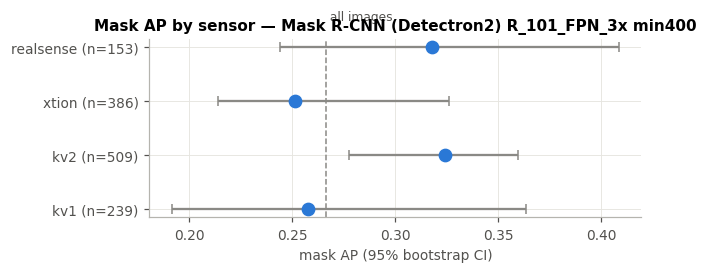

In [12]:
mt = ea.build_match_table(coco_gt, preds)
assert abs(ea.ap_from_weights(mt)[0] - ev["segm"]["AP"]) < 1e-12, "match table != COCOeval"

img_sensor = np.array([ea.image_sensor(coco_gt.imgs[i]) for i in mt.img_ids])
sens_rows = []
for s in ea.SENSORS:
    sub = img_sensor == s
    if not sub.any():
        continue
    ids = [i for i, f in zip(mt.img_ids, sub) if f]
    gt_s = ea.subset_coco(coco_gt, ids)
    ap_s = ea.segm_ap(gt_s, [p for p in preds if p["image_id"] in set(ids)])
    # the same number from the match table with 0/1 weights (sanity), + bootstrap CI
    assert abs(ea.ap_from_weights(mt, sub.astype(float))[0] - ap_s["AP"]) < 1e-9
    boot = ea.bootstrap_ap(mt, n_boot=N_BOOT // 2, seed=SEED, subset=sub)
    ci = ea.ci_summary(ap_s["AP"], boot.AP)
    sens_rows.append({"sensor": s, "n_images": int(sub.sum()),
                      "n_gt": len(gt_s.getAnnIds()), "mask_AP": ap_s["AP"],
                      "AP50": ap_s["AP50"], "ci_lo": ci["ci_lo"], "ci_hi": ci["ci_hi"],
                      "APs": ap_s["APs"], "APm": ap_s["APm"], "APl": ap_s["APl"]})
sens_df = pd.DataFrame(sens_rows).set_index("sensor")
sens_df.to_csv(OUT_DIR / "ap_by_sensor.csv")
print(sens_df.round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 2.6))
y = np.arange(len(sens_df))
ax.errorbar(sens_df.mask_AP, y, xerr=[sens_df.mask_AP - sens_df.ci_lo, sens_df.ci_hi - sens_df.mask_AP],
            fmt="o", ms=8, color=ea.PALETTE[0], ecolor="#8a8985", capsize=3, lw=1.5)
ax.axvline(ev["segm"]["AP"], color="#8a8985", ls="--", lw=1)
ax.text(ev["segm"]["AP"], len(sens_df) - 0.5, " all images", color="#52514e", fontsize=8)
ax.set_yticks(y, [f"{s} (n={n})" for s, n in zip(sens_df.index, sens_df.n_images)])
ax.set_xlabel("mask AP (95% bootstrap CI)")
ax.set_title(f"Mask AP by sensor — {run.label}")
fig.tight_layout(); fig.savefig(OUT_DIR / "ap_by_sensor.png"); plt.show()

---
## 4. Bootstrap CI of mask AP — the noise floor

Images are resampled with replacement (`N_BOOT` times) and AP is recomputed from
COCOeval's own per-detection matches (exact for the original sample, see the
assert above). The bootstrap SE is the *test-set* sampling noise: two models
evaluated independently on this test set cannot be told apart if their APs
differ by less than about 2·√2·SE. The paired test in notebook 10 is tighter,
because both models are resampled on the same images.

In [13]:
boot = ea.bootstrap_ap(mt, n_boot=N_BOOT, seed=SEED)
bs = pd.DataFrame([dict(metric=m, **ea.ci_summary(ap, boot[m]))
                   for m, ap in [("AP", ev["segm"]["AP"]), ("AP50", ev["segm"]["AP50"])]])
bs.to_csv(OUT_DIR / "bootstrap_ap.csv", index=False)
print(bs.round(4).to_string(index=False))
print("\nci_lo/ci_hi — percentile interval; basic_lo/basic_hi — bias-corrected (2θ − q) interval. "
      "The bootstrap distribution of AP is biased upwards (boot_bias): the interpolated precision "
      "is a running max, so resampling noise inflates it; the SE is unaffected.")
se = bs.set_index("metric").loc["AP", "boot_se"]
print(f"\nNoise floor: bootstrap SE of mask AP = {se:.4f} ({se*100:.2f} AP points). "
      f"Unpaired differences below ~{2*np.sqrt(2)*se*100:.1f} AP points between two "
      f"models on this {SPLIT} set ({mt.n_images} images) are not significant.")

metric  point  boot_se  ci_lo  ci_hi  boot_bias  basic_lo  basic_hi
    AP 0.2665   0.0144 0.2462 0.3022     0.0063    0.2307    0.2867
  AP50 0.4272   0.0189 0.3974 0.4730     0.0066    0.3814    0.4569

ci_lo/ci_hi — percentile interval; basic_lo/basic_hi — bias-corrected (2θ − q) interval. The bootstrap distribution of AP is biased upwards (boot_bias): the interpolated precision is a running max, so resampling noise inflates it; the SE is unaffected.

Noise floor: bootstrap SE of mask AP = 0.0144 (1.44 AP points). Unpaired differences below ~4.1 AP points between two models on this test set (1287 images) are not significant.


---
## 5. Galleries

Overlay legend: **red fill** — the detection under inspection (class, score);
**green** — GT of the evaluated classes; **yellow** — the GT targeted by the error
(the missed object); **thin grey** — annotations of all other classes in the
full SUN RGB-D COCO (`sunrgbd_instances_all.json`).

> **v1 audit (previous dataset version, Detectron2 R50-FPN std10, test AP 0.230).**
> A visual audit of the v1 predictions found that most high-confidence
> "background" FPs were **real furniture missing from the ground truth**, not
> model errors (`vkr_work/v1_error_analysis/renders/visual_audit_summary.csv`):
>
> | sample | viewed | real object, unlabeled | real object under an unmapped name | fragmentary GT | class-ambiguous | genuine model error | unclear |
> |---|---|---|---|---|---|---|---|
> | bkg FP, score ≥ 0.8 | 40 | 23 | 10 | 4 | 2 | **0** | 1 |
> | bkg FP, score 0.5–0.8 | 20 | 13 | 1 | 1 | 0 | **4** | 1 |
> | missed GT | 24 | – | – | 15 (slivers / fragments) | – | 9 (small / distant / occluded) | – |
>
> So 37 of 40 (≈ 93%) top-score background FPs and 15 of 20 (75%) mid-score ones
> were real objects. The 600 v1 background FPs with score ≥ 0.8 cost 3.5 AP points
> (5.9 AP50 points; `tables/bkg_by_score.csv`), and 156 of them (26%) overlapped
> an annotated object of a non-std10 class at IoU ≥ 0.5 (`tables/bkg_fp_vs_fullcoco.csv`).
> The v2 rebuild recovered many unmapped names, so these numbers are **not** v2
> results — the gallery below is the material for repeating the audit on v2.

bkg FP pool (score >= 0.8): 459 of 11015 bkg FPs; gallery of 16

What lies under bkg/both FPs with score >= 0.8 in the all-class COCO:
type  covered_by                 
bkg   nothing annotated              327
      other-class GT, IoU 0.1-0.5     43
      other-class GT, IoU >= 0.5      89
both  nothing annotated               48
      other-class GT, IoU 0.1-0.5      4
      other-class GT, IoU >= 0.5       2

most frequent other-class names under them (IoU >= 0.5): {'stool': 9, 'chairback': 4, 'cabinet': 2, 'bench': 2, 'tabletop': 2, 'mattress': 2, 'ottoman': 2, 'newspaper': 2, 'conferencetablechair': 2, 'pool table': 1}


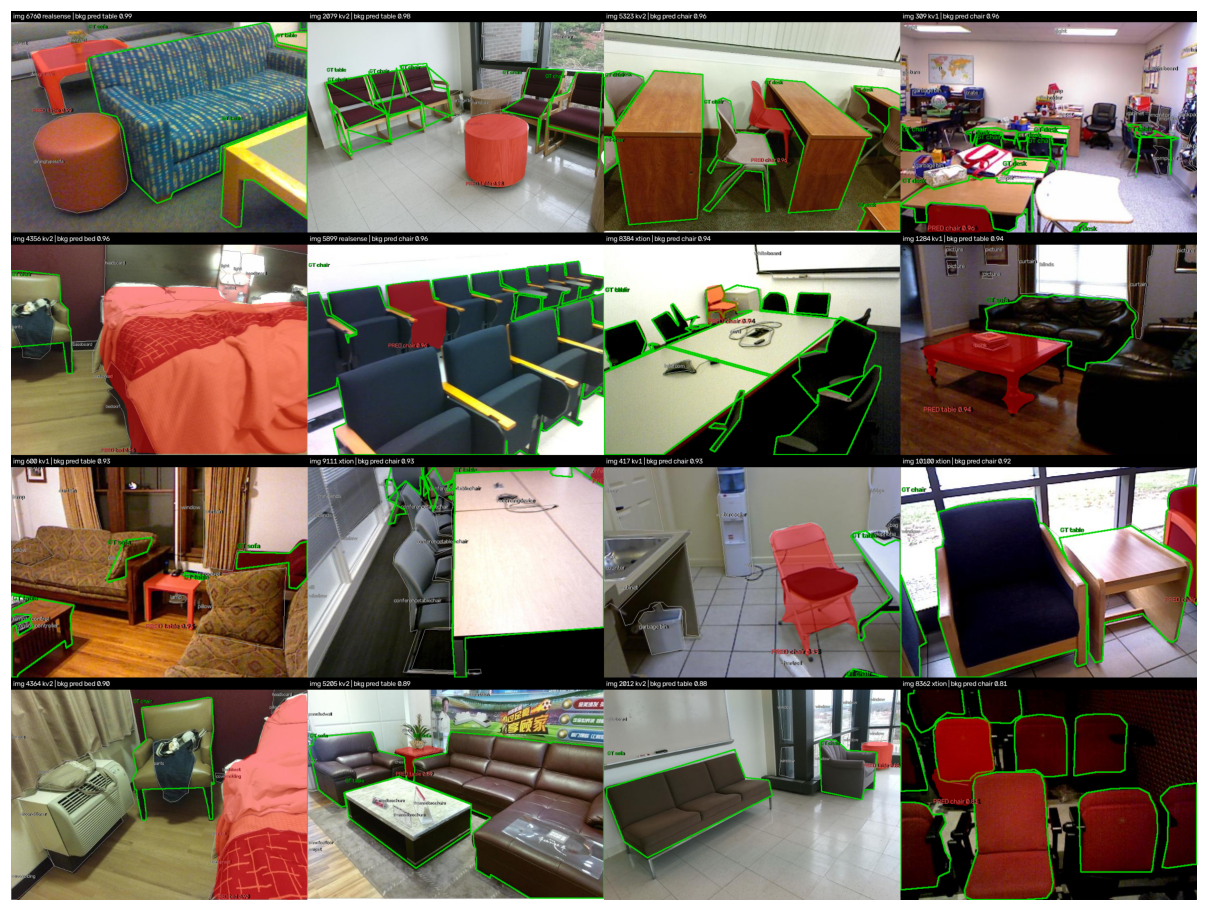

In [14]:
full_coco = ea.load_coco(FULL_COCO) if FULL_COCO.exists() else None
rng = np.random.default_rng(SEED)

def sample(df, n):
    return df.iloc[np.sort(rng.choice(len(df), size=min(n, len(df)), replace=False))] if len(df) else df

bkg_pool = rec[(rec.type == "bkg") & (rec.score >= 0.8)]
if len(bkg_pool) < N_GALLERY:
    print(f"[note] only {len(bkg_pool)} bkg FPs with score >= 0.8 -> taking the top-{N_GALLERY} by score")
    bkg_pool = rec[rec.type == "bkg"].nlargest(N_GALLERY, "score")
bkg_items = sample(bkg_pool, N_GALLERY).sort_values("score", ascending=False)
tiles = [ea.render_error_tile(coco_gt, preds, r.img, r.pidx, -1, "bkg", full_coco, DATASET_ROOT)
         for r in bkg_items.itertuples()]
ea.save_montage(tiles, OUT_DIR / "gallery_bkg_fp_high_score.png", ncols=4)
bkg_items[["img", "pidx", "cls_name", "score", "iou"]].to_csv(
    OUT_DIR / "gallery_bkg_fp_high_score_manifest.csv", index=False)
print(f"bkg FP pool (score >= 0.8): {len(rec[(rec.type == 'bkg') & (rec.score >= 0.8)])} "
      f"of {int((rec.type == 'bkg').sum())} bkg FPs; gallery of {len(tiles)}")

if full_coco is not None:
    under = ea.bkg_vs_full_coco(data, rec, full_coco, min_score=0.8)
    under.to_csv(OUT_DIR / "bkg_fp_vs_fullcoco.csv", index=False)
    if len(under):
        print("\nWhat lies under bkg/both FPs with score >= 0.8 in the all-class COCO:")
        print(under.groupby(["type", "covered_by"]).size().rename("n").to_string())
        top_names = under[under.other_iou >= 0.5].other_name.value_counts().head(10)
        print("\nmost frequent other-class names under them (IoU >= 0.5):", top_names.to_dict())

def show_png(path, w=14):
    im = plt.imread(path)
    plt.figure(figsize=(w, w * im.shape[0] / im.shape[1]))
    plt.imshow(im); plt.axis("off"); plt.show()

show_png(OUT_DIR / "gallery_bkg_fp_high_score.png")

missed GT: 505 of 5043 GT objects (10.0%); random sample of 16 (seed 0)


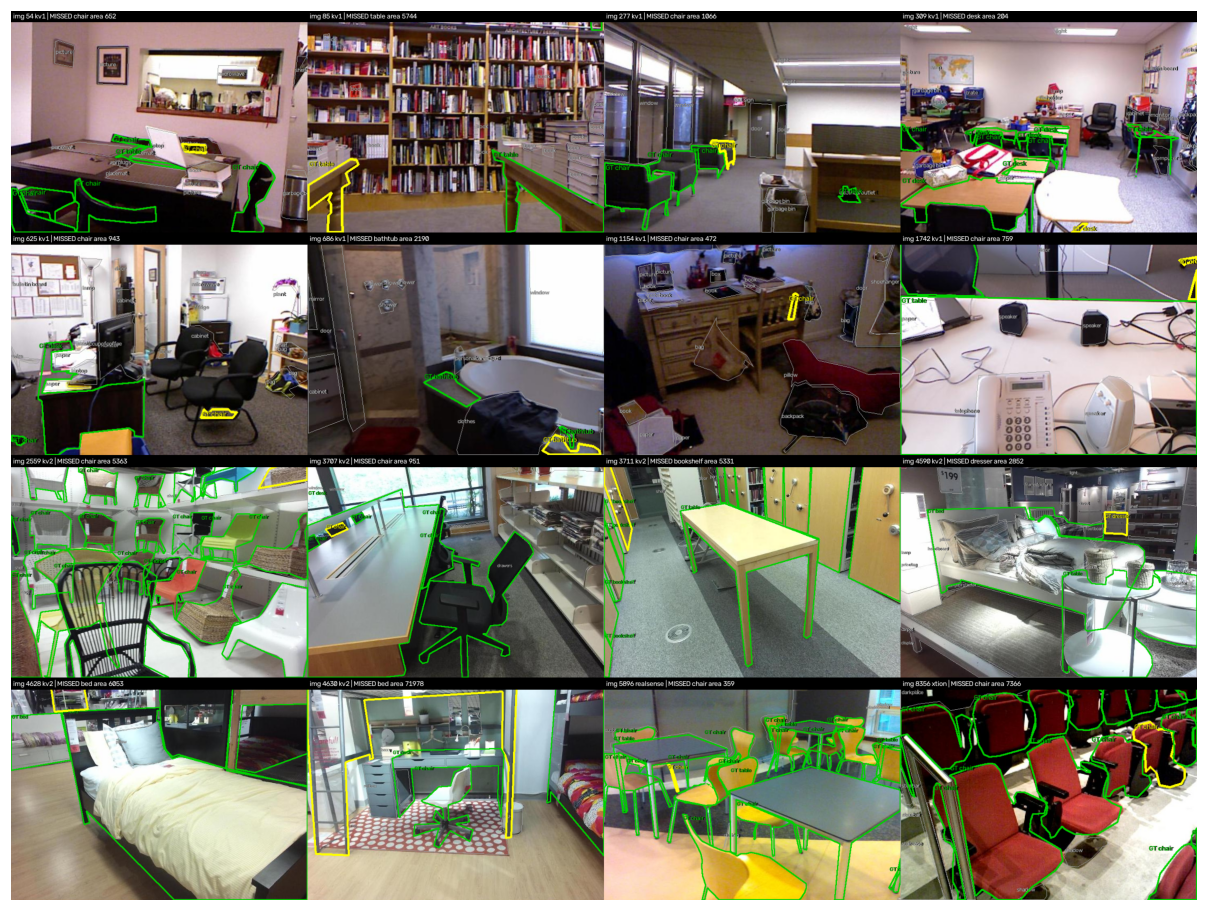

In [15]:
miss = [(img, gi) for (img, gi), v in gt_status.items() if v == "miss"]
idx = rng.choice(len(miss), size=min(N_GALLERY, len(miss)), replace=False) if miss else []
miss_items = sorted([miss[i] for i in idx])
tiles = [ea.render_error_tile(coco_gt, preds, img, -1, gi, "miss", full_coco, DATASET_ROOT)
         for img, gi in miss_items]
ea.save_montage(tiles, OUT_DIR / "gallery_missed_gt.png", ncols=4)
pd.DataFrame([{"img": img, "gi": gi, "class": NAMES[data.gts[img][gi][1]],
               "area": data.gts[img][gi][2]} for img, gi in miss_items]).to_csv(
    OUT_DIR / "gallery_missed_gt_manifest.csv", index=False)
print(f"missed GT: {len(miss)} of {len(gt_status)} GT objects "
      f"({len(miss)/max(len(gt_status),1):.1%}); random sample of {len(tiles)} (seed {SEED})")
show_png(OUT_DIR / "gallery_missed_gt.png")

**Best and worst images.** Selection rule: per-image F1 at score ≥ `CONF` and
mask IoU ≥ 0.5 (class-aware COCOeval matching), among images with at least
3 GT objects; ties broken by the number of GT objects. Left — GT, right —
predictions with score ≥ `CONF`.

selection rule: per-image F1 (score >= 0.5, IoU >= 0.5, class-aware), images with >= 3 GT objects (746 of 1287); ties -> more GT

best:
          n_gt   tp   fp   fn   f1
image_id                          
3716       9.0  9.0  0.0  0.0  1.0
2938       7.0  7.0  0.0  0.0  1.0
8386       6.0  6.0  0.0  0.0  1.0
1700       5.0  5.0  0.0  0.0  1.0


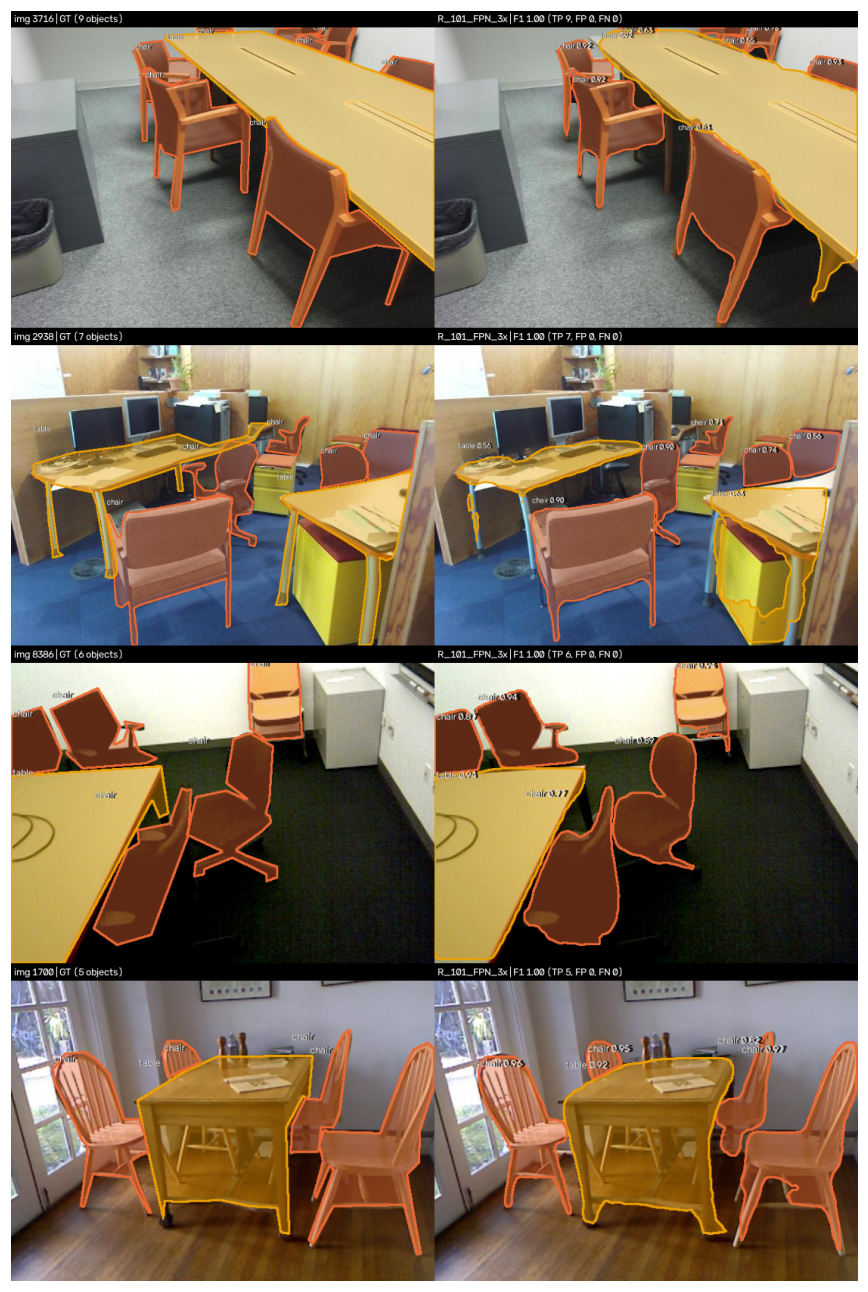


worst:
          n_gt   tp    fp    fn   f1
image_id                            
10248     14.0  0.0  10.0  14.0  0.0
10282     12.0  0.0   1.0  12.0  0.0
10246     10.0  0.0  12.0  10.0  0.0
10251     10.0  0.0  10.0  10.0  0.0


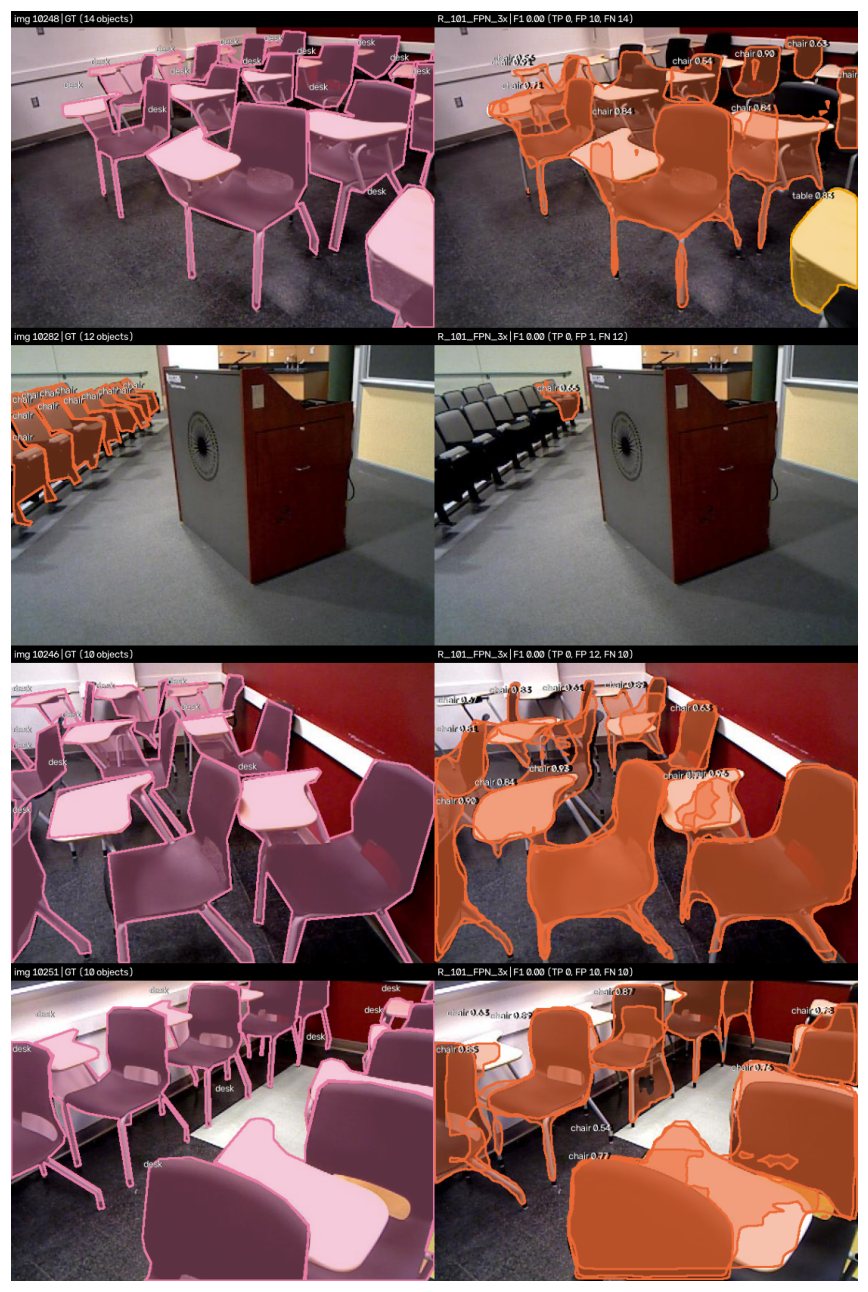

In [16]:
pim = ea.per_image_stats(mt, conf=CONF)
elig = pim[pim.n_gt >= 3]
print(f"selection rule: per-image F1 (score >= {CONF}, IoU >= 0.5, class-aware), "
      f"images with >= 3 GT objects ({len(elig)} of {len(pim)}); ties -> more GT")
preds_by_img = {}
for p in preds:
    preds_by_img.setdefault(p["image_id"], []).append(p)
for tag, sel in [("best", elig.sort_values(["f1", "n_gt"], ascending=[False, False]).head(4)),
                 ("worst", elig.sort_values(["f1", "n_gt"], ascending=[True, False]).head(4))]:
    tiles = []
    for img_id, r in sel.iterrows():
        tiles.append(ea.render_predictions_tile(coco_gt, [], img_id, f"img {img_id} | GT ({int(r.n_gt)} objects)",
                                                show_gt=True, root=DATASET_ROOT))
        tiles.append(ea.render_predictions_tile(
            coco_gt, preds_by_img.get(img_id, []), img_id,
            f"{run.backbone} | F1 {r.f1:.2f} (TP {int(r.tp)}, FP {int(r.fp)}, FN {int(r.fn)})",
            conf=CONF, root=DATASET_ROOT))
    ea.save_montage(tiles, OUT_DIR / f"qualitative_{tag}.png", ncols=2)
    sel.to_csv(OUT_DIR / f"qualitative_{tag}_manifest.csv")
    print(f"\n{tag}:"); print(sel.round(3).to_string())
    show_png(OUT_DIR / f"qualitative_{tag}.png", w=10)

---
## 6. TIDE profile: Mask R-CNN vs YOLOv8-seg

The same decomposition for the comparison run (default: YOLOv8s-seg std10) on the
same test GT. Expected contrast: the single-stage YOLO trades recall (*miss*)
for mask precision (*mask quality*), the two-stage Mask R-CNN the other way.

[i] v2_yolov8seg_std10/test_predictions.json: 13158 predictions on 1283/1287 GT images


[ok] exact pycocotools reproduction for v2_yolov8seg_std10


  cls   dAP50 +0.1176  dAP +0.0641


  loc   dAP50 +0.0849  dAP +0.0589


  both  dAP50 +0.0042  dAP +0.0022


  dupe  dAP50 +0.0044  dAP -0.0040


  bkg   dAP50 +0.0646  dAP +0.0378


  miss  dAP50 +0.0986  dAP +0.0601


base AP: R_101_FPN_3x 0.2665 | YOLOv8s-seg 0.2427
base AP50: R_101_FPN_3x 0.4272 | YOLOv8s-seg 0.3907

                                     count                    dAP50                      dAP            
                              R_101_FPN_3x YOLOv8s-seg R_101_FPN_3x YOLOv8s-seg R_101_FPN_3x YOLOv8s-seg
error                                                                                                   
cls                                   2235         785       0.0614      0.1176       0.0264      0.0641
loc                                   4501        2724       0.0893      0.0849       0.0606      0.0589
both                                  2125         733       0.0064      0.0042       0.0033      0.0022
dupe                                  1492        1024       0.0018      0.0044      -0.0021     -0.0040
bkg                                  11015        4653       0.0988      0.0646       0.0584      0.0378
miss                                   505         833   

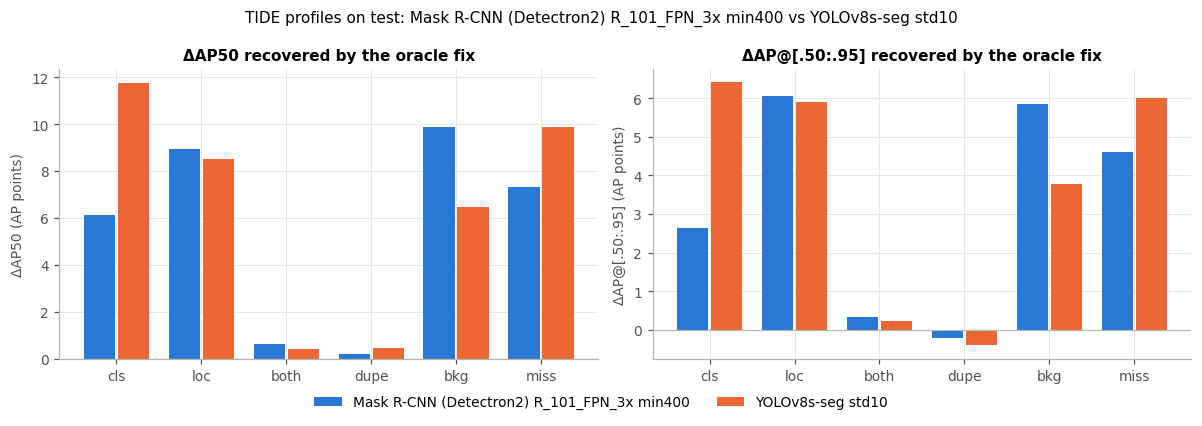


            AP R_101_FPN_3x  AP YOLOv8s-seg  miss R_101_FPN_3x  miss YOLOv8s-seg  tp IoU R_101_FPN_3x  tp IoU YOLOv8s-seg
class                                                                                                                    
bed                   0.289           0.306                 26                29                0.805               0.808
chair                 0.215           0.225                221               337                0.758               0.757
sofa                  0.282           0.256                 38                48                0.829               0.816
table                 0.260           0.246                103               211                0.781               0.788
desk                  0.069           0.056                 61               116                0.748               0.779
toilet                0.579           0.526                  0                 4                0.841               0.831
dresser               0

In [17]:
cmp_run = None
if COMPARE_DIR:
    cmp_run = ea.parse_run(Path(COMPARE_DIR).expanduser())
else:
    cmp_run = next((r for r in runs if r.family == "yolov8seg" and r.config == EVAL_CONFIG), None)

if cmp_run is None or "test" not in cmp_run.files:
    print("[skip] no comparison run (YOLOv8-seg) with test predictions found — section skipped")
elif cmp_run.config == "std10" and EVAL_CONFIG != "std10":
    print(f"[skip] comparison run {cmp_run.name} (std10) cannot be scored on {EVAL_CONFIG}")
else:
    preds_c = ea.load_preds(cmp_run.files[SPLIT], coco_gt)
    data_c = ea.TideData(coco_gt, preds_c)
    chk_c = ea.check_tide_vs_cocoeval(data_c)
    assert chk_c.attrs["exact"], "TIDE AP does not reproduce pycocotools for the comparison run"
    print(f"[ok] exact pycocotools reproduction for {cmp_run.name}")
    tide_c = ea.run_tide(data_c)
    A, B = run.backbone, cmp_run.backbone            # short column labels
    sa, sb = summary.set_index("error"), tide_c["summary"].set_index("error")
    both = pd.concat({(m, k): t[m] for m in ["count", "dAP50", "dAP"]
                      for k, t in [(A, sa), (B, sb)]}, axis=1)
    both.to_csv(OUT_DIR / "tide_vs_compare.csv")
    print(f"base AP: {A} {tide['base_AP']:.4f} | {B} {tide_c['base_AP']:.4f}")
    print(f"base AP50: {A} {tide['base_AP50']:.4f} | {B} {tide_c['base_AP50']:.4f}\n")
    print(both.round(4).to_string())
    plot_tide_bars({run.label: summary, cmp_run.label: tide_c["summary"]},
                   OUT_DIR / "tide_vs_compare.png",
                   f"TIDE profiles on {SPLIT}: {run.label} vs {cmp_run.label}")
    pc_c = tide_c["per_class"]
    pc_cmp = pd.DataFrame({f"AP {run.backbone}": per_class.AP, f"AP {cmp_run.backbone}": pc_c.AP,
                           f"miss {run.backbone}": per_class.miss, f"miss {cmp_run.backbone}": pc_c.miss,
                           f"tp IoU {run.backbone}": per_class.mean_tp_iou,
                           f"tp IoU {cmp_run.backbone}": pc_c.mean_tp_iou})
    pc_cmp.to_csv(OUT_DIR / "tide_vs_compare_per_class.csv")
    print(); print(pc_cmp.round(3).to_string())

In [18]:
print("Outputs in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:45s} {p.stat().st_size/1024:8.1f} KB")

Outputs in outputs/error_analysis/v2_maskrcnn_detectron2_min400_R_101_FPN_3x_on_std10
  ap_by_sensor.csv                                   0.6 KB
  ap_by_sensor.png                                  34.6 KB
  ap_by_size.csv                                     0.4 KB
  bkg_by_score.csv                                   0.3 KB
  bkg_fp_vs_fullcoco.csv                            45.7 KB
  bootstrap_ap.csv                                   0.3 KB
  confusion_matrix.csv                               0.4 KB
  confusion_matrix.png                              89.4 KB
  confusion_pairs.csv                                1.2 KB
  gallery_bkg_fp_high_score.png                   5134.1 KB
  gallery_bkg_fp_high_score_manifest.csv             0.8 KB
  gallery_missed_gt.png                           5747.7 KB
  gallery_missed_gt_manifest.csv                     0.3 KB
  merged_pair_ap.csv                                 0.4 KB
  qualitative_best.png                            2502.5 KB
  qualitative_